# Week 5 · Your Week 4 work, reviewed, and how this week works

I read your Week 4 log (24.5 hours, Nov 2–9), your mock exam result (over 90) and every cell you added or changed. Two things in your notes shaped this whole week. First, your own explanations (the PCA proposition, the Lloyd's algorithm card, the k-distance note) were better than mine, so **B** lists what they do differently, and every notebook this week is written that way. Second, you wrote that you're weak at Python and want to stop "doing mindless iterations everytime", so **C** is a practice plan, and notebook `01` is the first part of it. **D** answers your question about how `linkage_distance` is used in hierarchical clustering. This is a light day: the OIBC deadline is Friday.

**How to use this notebook**
- Run cells one at a time with **Shift + Enter**.
- Before running an example, **guess what it prints**. The real result is written after `# →` in the comments, so you can check yourself.
- **Your turn** cells are for you. Open **Show one answer** only after a real attempt.
- If things get weird, click **Restart** at the top and run from the top again.

**Run this cell first.** It loads NumPy, the picture helpers (`figures.py` in this folder) and the exercise checker.

In [45]:
import numpy as np
import matplotlib.pyplot as plt
from figures import *
import checks; checks.load(globals(), "00")      # defines check(n)

## M. The map: what's in this notebook and why

🖼 **Picture.** This week. Deep learning starts in `02`; `01` comes first because every DL formula this week becomes a line of NumPy, and that translation is the skill you asked to practise.

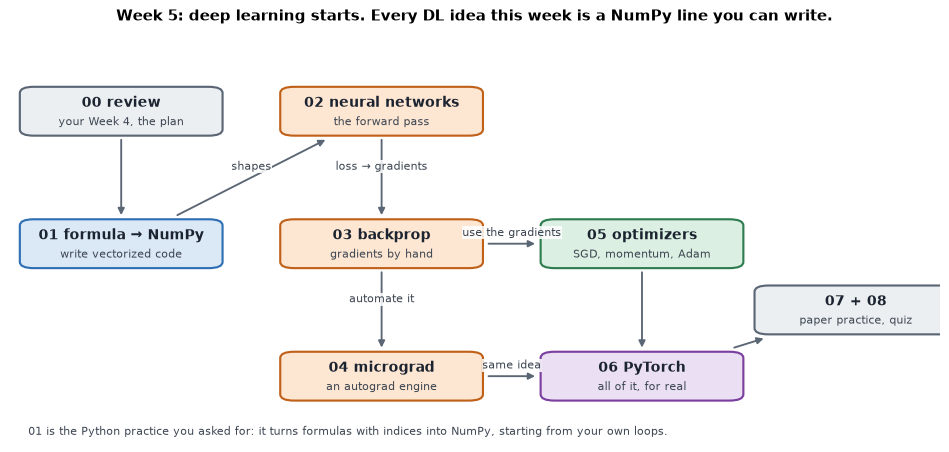

In [46]:
fig_week5_map()

| Section | What | Why it's here |
|---|---|---|
| 0 | recap, and one function from memory | Week 4 closed book; exercise 1 is the first **code-from-memory** warm-up (part of the practice plan in C) |
| A | your Week 4 code and notes, reviewed | what was right, what to change, and answers to the questions in your cells and log |
| B | your explanations vs mine | you asked me to compare them and adopt the differences; these are the new rules |
| C | Python: the practice plan | "I am weak in python programming. Think of how we can practice this." |
| D | how `linkage_distance` builds a hierarchy | you asked how your exercise-1 function is used; it's the inner step of agglomerative clustering |

## 0. Recap first · 10 min, closed book

**Quick check:** Data centred, $S$ its covariance matrix, $u$ a unit vector. What is the variance of the projections $s_i = u^\top x_i^c$, and why must $\lVert u \rVert = 1$?

<details><summary>Answer</summary>

$\operatorname{Var}(s) = u^\top S u$. Without $\lVert u \rVert = 1$, $v = c\,u$ would give $c^2\, u^\top S u$: the length of $v$, not the spread of the data. (Your Proposition and Remark 2.) [Week 4 · 02 §3 ↗](../week4/02_pca.ipynb)

</details>

**Quick check:** Which objective does k-means lower, and why can neither step raise it?

<details><summary>Answer</summary>

$J = \sum_i \lVert x_i - \mu_{c(i)} \rVert^2$. Assign: each point picks its nearest centroid, so each term can only shrink. Update: the mean is the point with the smallest sum of squared distances to the cluster's members. [Week 4 · 03, your Lloyd's algorithm card ↗](../week4/03_kmeans.ipynb)

</details>

**Quick check:** Write the responsibility $r_{ik}$ of a Gaussian mixture.

<details><summary>Answer</summary>

$r_{ik} = \frac{\pi_k\, \mathcal{N}(x_i \mid \mu_k, \sigma_k^2)}{\sum_j \pi_j\, \mathcal{N}(x_i \mid \mu_j, \sigma_j^2)}$: the share of point $i$ that bump $k$ explains. Each row of $R$ sums to 1. [Week 4 · 04 §3 ↗](../week4/04_hierarchical_dbscan_gmm.ipynb)

</details>

**Quick check:** DBSCAN: what happens if $\varepsilon$ is much too small? Much too large?

<details><summary>Answer</summary>

Too small: almost no point has `min_pts` neighbours, so almost everything is noise. Too large: everything is within $\varepsilon$ of everything, so all points form one cluster. The k-distance plot picks the knee in between. [Week 4 · 04 §2 ↗](../week4/04_hierarchical_dbscan_gmm.ipynb)

</details>

**Quick check:** AdaBoost: the vote $\alpha$ of a stump with weighted error $\varepsilon$, and what happens to the weights next?

<details><summary>Answer</summary>

$\alpha = \frac{1}{2}\ln\frac{1 - \varepsilon}{\varepsilon}$. Misclassified points are multiplied by $e^{\alpha}$, correct ones by $e^{-\alpha}$, then all are divided by their sum. [Week 4 · 01 §5–6 ↗](../week4/01_boosting_step_by_step.ipynb)

</details>

**Code from memory.** From now on, every notebook's section 0 ends with one function from an earlier notebook, written closed book. Write it on paper first if you can, then type it and run the check. If you can't start, write the loop version: that counts.

**Exercise 1 · PCA, from memory.** Return `(mean, components)`: `mean` is `(d,)`; `components` is `(k, d)`, the $k$ eigenvectors of the covariance matrix $S = \frac{1}{n-1} X_c^\top X_c$ with the largest eigenvalues, **one per row**, largest first. `np.linalg.eigh` returns eigenvalues in **ascending** order, with the eigenvectors as **columns**.

**Example**: what goes in, and what should come out:
```python
X = np.array([[1.0, 1.0], [2.0, 2.0], [3.0, 3.0], [4.0, 4.5]])     # (4, 2), float
mean, comps = pca_fit(X, 1)
mean     # → [2.5   2.625]
comps    # → [[0.654 0.757]]     (or the same row times -1: a direction's sign is arbitrary)
```

In [47]:
def pca_fit(X, k):
    mean = X.mean(axis=0)
    Xc = X - mean
    S = Xc.T @ Xc / (len(X) - 1)
    eig_vals, eig_vec = np.linalg.eigh(S)         
    order = np.argsort(eig_vals)[::-1][:k]        
    return mean, eig_vec[:, order].T        

In [48]:
check(1)

Exercise 1: PASS


## A. Your Week 4 code and notes, reviewed

Most important first. Each point opens with what you wrote, linked back to it.

**A1. The ML checkpoint: passed**

Over 90 on the 90-minute mock exam, on paper, is a strong result: the ML half of the lab exam is in good shape. Your log shows where the time actually went: the theory was fine, and the hard parts were **writing** code (EM, the class exercises, k-means exercise 4). That's what this week trains. If you remember which mock questions cost points, add them to the tracker log by topic; the recaps are built from them.

**A2. `update_weights` changes the caller's array**

> ↩ **Recap** · [Week 4 · 01 exercise 5 (update the weights) ↗](../week4/01_boosting_step_by_step.ipynb)
>
> You wrote `for i in range(len(yh)): w[i] = w[i]*np.exp(-1*yh[i]*alpha)`, then `w = w/w.sum()`, then `return w`. It passed.

The numbers it returns are right. The problem is what it does to the array that was passed **in**. Inside the function, `w` is a second name for the caller's array (Python passes the array itself, not a copy), so `w[i] = ...` writes into the caller's array. Then `w = w / w.sum()` creates a new array and moves only the local name `w` to it. The caller is left holding an array that was changed and doesn't sum to 1:

🖼 **Picture.** Four points, equal weights 0.25, the second one misclassified, $\alpha = 0.549$. Step 2 writes $0.25\,e^{\mp 0.549}$ into the caller's array; step 3 makes a new array for the return value.

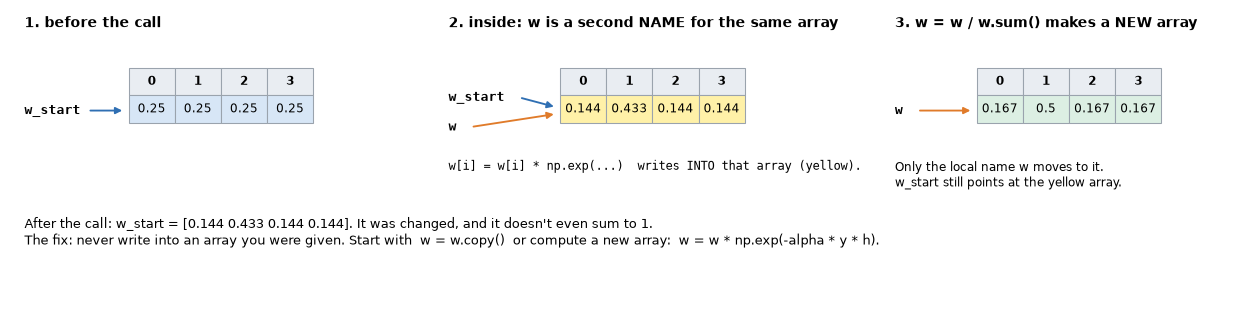

In [49]:
fig_shared_array()

In [50]:
def update_weights(w, y, h, alpha):        # your version
    yh = y * h
    for i in range(len(yh)):
        w[i] = w[i] * np.exp(-1 * yh[i] * alpha)   # writes into the caller's array
    w = w / w.sum()                               # a new array; only the local name moves
    return w

w_start = np.full(4, 0.25)
y = np.array([1, 1, -1, -1]); h = np.array([1, -1, -1, -1])
new = update_weights(w_start, y, h, 0.549)
print(new.round(3))        # → [0.167 0.5   0.167 0.167]   correct
print(w_start.round(3))    # → [0.144 0.433 0.144 0.144]   changed, and not normalized

[0.167 0.5   0.167 0.167]
[0.144 0.433 0.144 0.144]


In `adaboost_fit` you passed the weights you owned, so nothing broke. It bites when a caller keeps using its array afterwards, for example to compare the weights before and after one round. Week 4 · 00 A4 was the same lesson with `w -= ...`. **The rule: never write into an array you were given.** Either compute a new array in one line (no loop needed: `w * np.exp(-alpha * y * h)` works on all entries at once), or start with `w = w.copy()`. In PyTorch next week the rule has one deliberate exception: the optimizer changes the model's weights in place, on purpose.

**Exercise 2 · Reweight without touching the input.** $w_i^{\text{new}} = \dfrac{w_i\, e^{-\alpha y_i h_i}}{\sum_j w_j\, e^{-\alpha y_j h_j}}$. `w`, `y`, `h` are `(n,)` (`y`, `h` hold $\pm 1$), `alpha` is a float. Return the new weights, **shape `(n,)`**, and leave `w` unchanged (the check verifies both). One line plus the division, no loop.

**Example**: what goes in, and what should come out:
```python
w = np.full(4, 0.25); y = np.array([1, 1, -1, -1]); h = np.array([1, -1, -1, -1])
reweight(w, y, h, 0.549)    # → [0.167 0.5   0.167 0.167]
w                           # → [0.25 0.25 0.25 0.25]   unchanged
```

In [51]:
def update_weights(w, y, h, alpha):        # your version
    yh = y * h
    for i in range(len(yh)):
        w[i] = w[i] * np.exp(-1 * yh[i] * alpha)   # writes into the caller's array
    w = w / w.sum()                               # a new array; only the local name moves
    return w

In [52]:
def reweight(w, y, h, alpha):
    yh = y * h
    w_new = w.copy()
    for i in range(len(yh)):
        w_new[i] = w_new[i] * np.exp(-1 * yh[i] * alpha)
    w_new = w_new / w_new.sum()
    return w_new

In [53]:
check(2)

Exercise 2: PASS


**A3. Does `count_leaves` work for a tree of any depth? Yes, and here's the proof**

> ↩ **Recap** · [Week 4 · 00 exercise 3 (count the leaves) ↗](../week4/00_week3_review.ipynb)
>
> You wrote (after looking up the solution): *"Nice recursion. Does this return the total number of leaves in a tree no matter how deep the tree is?"* The function: a leaf returns 1; a node returns `count_leaves(left) + count_leaves(right)`.

**Proposition.** For every finite tree $t$, `count_leaves(t)` returns the number of leaves of $t$.

**Proof** (induction on the depth $d$ of $t$). *Base case,* $d = 0$: $t$ is a single leaf, and the function returns 1, which is correct. *Induction step,* $d \ge 1$: assume the function is correct for every tree of depth less than $d$. Then $t$ is a node with subtrees $L$ and $R$, each of depth at most $d - 1$, so `count_leaves(L)` and `count_leaves(R)` are correct by assumption. Every leaf of $t$ lies in exactly one of $L$ and $R$, so the number of leaves of $t$ is their sum, which is what the function returns. $\blacksquare$

**Remarks.** (1) "Trust the recursive call" is exactly the induction assumption: you only check that the base case is right and that the combining step is right; the depth never enters the argument. (2) The depth changes how many calls happen (one per node), not whether the answer is right. (3) The only practical limit is Python's recursion limit, about 1000 nested calls: a tree more than ~1000 levels deep would raise `RecursionError`. Decision trees are never that deep.

**A4. `covariance`: correct; `len(Xc)` is enough**

> ↩ **Recap** · [Week 4 · 02 exercise 2 (covariance) ↗](../week4/02_pca.ipynb)
>
> You wrote `S = Xc.T@Xc/(len(Xc[:,:1])-1)`.

Correct. `Xc[:, :1]` is the first column kept as a column, shape `(n, 1)`, and `len` of it is $n$. But `len` of any array is the length of its **first** axis, so `len(Xc)` is already $n$ (or write `Xc.shape[0]`, which says it more clearly).

In [54]:
Xc = np.zeros((5, 3))
print(len(Xc), Xc.shape[0], len(Xc[:, :1]))    # → 5 5 5

5 5 5


**A5. `n_components_for`: a clever count, with one edge case**

> ↩ **Recap** · [Week 4 · 02 exercise 7 (how many components) ↗](../week4/02_pca.ipynb)
>
> You wrote `cs = np.cumsum(values)/np.sum(values)` then `return len(values) - len(cs[cs>=target]) + 1`.

It works because the cumulative shares only go up: once they reach the target they stay above it. So `cs[cs >= target]` is a tail of `cs`, and $n$ minus the tail's length is the number of entries **before** the first one that reaches the target; +1 counts that one too. With `values = [4, 2.5, 1.5, 1, 1]` and target 0.8: `cs = [0.4, 0.65, 0.8, 0.9, 1.0]`, the tail has 3 entries, so $5 - 3 + 1 = 3$. The more common one-liner is `np.argmax(cs >= target) + 1` (`argmax` of True/False returns the position of the **first** True).

**The edge case.** Floating-point sums aren't exact. Ten shares of 0.1 add up to `0.9999999999999999`, not 1.0, so with `target=1.0` no entry passes and your formula returns $n + 1$ (the `argmax` version is worse: with no True it returns position 0, so 1 component). A tolerance fixes both:

In [55]:
vals = np.full(10, 0.1)
cs = np.cumsum(vals) / vals.sum()
print(cs[-1] == 1.0, cs[-1])                       # → False 0.9999999999999999
print(len(vals) - len(cs[cs >= 1.0]) + 1)          # → 11   one more than there are
print(int(np.argmax(cs >= 1.0 - 1e-9)) + 1)        # → 10   with a tolerance

False 0.9999999999999999
11
10


**A6. `dbscan_core`: you found the better way yourself**

> ↩ **Recap** · [Week 4 · 04 exercise 2 (core points) ↗](../week4/04_hierarchical_dbscan_gmm.ipynb)
>
> You looped over the rows of the distance table `D`, appended `np.count_nonzero(row<=eps) >= min_pts`, and asked *"is there a better way to write this?"*. Then, in a comment: `return (D <= eps).sum(axis=1) >= min_pts`, "a cleaner way".

Yes, your comment is the better way. Look at what changed: the loop **went over the rows** and **counted along each row**. The one-liner does the counting along axis 1 for all rows at once: `D <= eps` is an `(n, n)` True/False table, `.sum(axis=1)` counts the Trues in each row (True counts as 1), shape `(n,)`, and `>= min_pts` compares each count. **"Loop over $i$, reduce along each row" always becomes "reduce along axis 1".** `01` turns that observation into a rule you can apply to any loop.

**A7. `e_step` and `m_step`: your loop was right**

> ↩ **Recap** · [Week 4 · 04 exercises 4–5 (E-step, M-step) ↗](../week4/04_hierarchical_dbscan_gmm.ipynb)
>
> You wrote a correct double loop for the E-step (`for i ...: for k ...: l2.append(pi[k]*gaussian_pdf(x[i], mu[k], var[k]))`), then the one-line version `m = pi[None, :] * gaussian_pdf(x[:, None], mu[None, :], var[None, :])`, and logged that you couldn't understand the one-liner or the M-step lines such as `mu = (R*x[:,None]).sum(axis=0)/Nk`.

Your loop shows you understood the formula; the gap is only the translation. `01` §3 starts from **your loop** and turns it into the one-liner, one mechanical step at a time, with a picture of every array; §4 does the same for each M-step line. By the end you write both from the formula alone (exercises 2 and 4 there).

**A8. The `\times` bug: "what does imes 2 mean?"**

> ↩ **Recap** · [Week 4 · 02 §E ↗](../week4/02_pca.ipynb)
>
> A line read "PC1 score $= 0.707$ imes 2 + ...". You asked what "imes" means.

My bug, and a Python lesson. In a normal Python string, a backslash starts an **escape**: `"\n"` is a newline and `"\t"` is a TAB character. So the LaTeX `\times` (×) inside a normal string became a TAB followed by `imes`. A **raw string**, `r"..."`, keeps every backslash as written. I fixed it in your notebook (your question is still there), on the Study Pack page and in my source files, and every build now scans for stray control characters.

In [56]:
print(len("\times"), len(r"\times"))     # → 5 6   the first is TAB + "imes"
print(repr("\times"))                      # → '\times'
print(repr("\times"[0]))                   # → '\t'   one character: a TAB

5 6
'\times'
'\t'


**A9. Your notes**

| Where | Your note | Verdict |
|---|---|---|
| [02 §3 ↗](../week4/02_pca.ipynb) | Proposition (variance of projections) with proof, four remarks and an example | Correct, and better than my version. It's the model for every derivation this week (section B). |
| [03 §E ↗](../week4/03_kmeans.ipynb) | Lloyd's algorithm: goal, steps with iteration index, why it works, caveats, cost, example table | Correct. "It must terminate" (finitely many assignments, $J$ never increases) is the argument most textbooks skip. |
| [04 §2 ↗](../week4/04_hierarchical_dbscan_gmm.ipynb) | Why the (minPts − 1)-th neighbour; why sort; a tiny 1-D example | Correct, and the hand-traced table is exactly what made it clear. |
| [04 §2 ↗](../week4/04_hierarchical_dbscan_gmm.ipynb) | "The main idea about DBSCAN is to use DENSITY as the deciding factor" | The whole method in one line. |
| [04 ex. 1 ↗](../week4/04_hierarchical_dbscan_gmm.ipynb) | the distance table for 1, 2, 4, 8, 13 | Right. Section D below uses it to run the whole algorithm. |
| [02 ex. 8 ↗](../week4/02_pca.ipynb) | "np.linalg.svd doesn't center for you!" | Exactly the trap: PCA by SVD needs `Xc`, not `X`. |

**Not done: the mini-project (`05`).** You skipped it for the OIBC deadline; that's the right call. Its from-scratch core, logistic regression by gradient descent, comes back as `02`'s warm-up, so you'll still write it.

## B. Your explanations vs mine: the new rules

You asked me to compare my explanations with the ones you added and adopt the differences. Here they are, side by side. The pattern: mine stated results and showed code; yours **named everything precisely, gave a reason for every step and every assumption, and used a fixed format** you can scan.

|  | Mine (Week 4) | Yours | The rule from now on |
|---|---|---|---|
| Symbols | used before being defined; shapes in passing | the setting first: $X_c \in \mathbb{R}^{n \times p}$, row $i$ is $(x_i - \bar x)^\top$, $u$ a unit vector | an **anatomy table** before any formula: symbol, shape, what a row / column / entry is |
| Derivations | one line, "where it comes from" | **Proposition → Proof** (aligned steps, one move per line) **→ Remarks → Example** | every derivation in this format; the example is checked two ways |
| Assumptions | not mentioned | Remark 2: why $\lVert u \rVert = 1$ is needed ($v = c\,u$ gives $c^2$ times the variance) | say what each assumption is for, and what breaks without it |
| Algorithms | a paragraph plus code | **Goal** (the objective) **→ Steps** (with iteration $t$) **→ Why it works → Caveats → Cost → Example** | every algorithm as a card in this format |
| Tuning knobs | "pick $\varepsilon$ at the knee" | why the (minPts − 1)-th neighbour; why sort; what each side of the knee means | for each knob: why it exists, what too small and too large do |
| Examples | numbers printed by code | a tiny example traced by hand, in a table | a hand-traced table for every new procedure, then the same numbers from code |
| Code comments | short | `init=` gives the starting centroids, `n_init=1` runs once, `.fit` runs Lloyd's algorithm | comment what each library call's arguments do and what it returns |
| Endings | a summary line | a recipe (the DBSCAN steps, the k-distance procedure) | end each section with a **recipe** you can reuse |

Where you'll see each format this week: the proposition that no single neuron can compute XOR, with its proof, in `02` §2; the proposition that the softmax-plus-cross-entropy gradient is $p - y$ in `02` §7; algorithm cards for backpropagation (`03` §5), the autograd engine's backward pass (`04` §3), Adam (`05` §5) and the PyTorch training loop (`06` §5); anatomy tables for every weight matrix. The ✏️ pencil is gone from exercise titles, as in your edits.

## C. Python: the practice plan

**Diagnosis.** From your Week 4 code: you can **read** a vectorized line once it's explained, and you can **write** a correct loop (your E-step loop was right). What's missing is the step in between: going from a formula, or from your own loop, to the vectorized line. Without a method for that step, the only option is to write the loop every time, which is the "mindless iterations" you described. So the plan is a method, then a lot of short, checked repetitions of it.

| Part | What | Where | How often |
|---|---|---|---|
| 1. A method | formula → indices → shapes → `None` → combine → sum → check, in six steps | `01` (Days 2–4, light days) | once, then used everywhere |
| 2. Loop first, then translate | always allowed: write the loop, then translate it line by line with `01` §5's table | every exercise | whenever stuck |
| 3. Code from memory | one earlier function, closed book, checked, at the end of each section 0 | exercise 1 of every notebook | daily |
| 4. Model as a class, next to the package | your own MLP and autograd engine, compared number for number with PyTorch | `02`, `03`, `04`, `06` | every model |
| 5. Read PyTorch code | what shape is this, what does it print, find the bug | `06` §10, `07` Part III | this week and every DL week |
| 6. The rebuild list | the functions below, each written on paper in under 5 minutes | this table | tick them off in your notes |

| Rebuild list: function | From | Comes back as a warm-up in |
|---|---|---|
| `softmax_rows`, `one_hot`, `cross_entropy` | Week 3 · 02; `01` §9 | `01` ex 1 |
| `pairwise_sq_dists` (any `(m, d)` and `(p, d)`) | Week 3 · 02; `01` §5 | `07` |
| `pca_fit` | Week 4 · 02 | this notebook, ex 1 |
| k-means: assign + update | Week 4 · 03 | `07` |
| `e_step`, `m_step` | Week 4 · 04; `01` §3–4 | `04` ex 1, `06` ex 1 |
| logistic regression gradient | Week 3 · 01; Week 4 · 05 | `02` ex 1 |
| `dense_forward`, `dense_backward` | `01` §7–8 | `03` ex 1 |
| `numerical_grad` | `03` §6 | `05` ex 1 |
| MLP training step in NumPy | `03` | `07` |
| `adam_step` | `05` | `08` quiz |
| the PyTorch training loop | `06` §5 | `07`, `08` |

**How to use a solution without it turning into copying.** (1) Give each exercise 15 real minutes; writing the loop version counts as real. (2) If you're stuck, look only at the **shapes** in the description and the example (they tell you a lot), then try again. (3) If you do read the solution, close it and rewrite the function from a blank cell, then add it to the rebuild list: it comes back as a warm-up a few days later, and that second, closed-book attempt is where it actually sticks.

## D. How `linkage_distance` builds a hierarchy

> ↩ **Recap** · [Week 4 · 04 exercise 1 (linkage distance), and your table ↗](../week4/04_hierarchical_dbscan_gmm.ipynb)
>
> You wrote `linkage_distance(A, B, how)`: build the `(m, p)` table of all distances between the points of cluster `A` and cluster `B`, then return its `min` (single), `max` (complete) or `mean` (average). You also wrote the distance table for the points 1, 2, 4, 8, 13. Your question in the log: how is this function actually **used** in hierarchical clustering?

**Answer in one line:** agglomerative clustering starts with every point as its own cluster, calls `linkage_distance` on **every pair of current clusters**, merges the closest pair, and repeats. Your function is the inner step: it decides what "closest" means for two **groups** of points (for two single points, all three linkages are just the distance).

**Algorithm card: agglomerative (bottom-up) hierarchical clustering**

**Goal.** A hierarchy of merges, from $n$ clusters of one point down to one cluster, recorded with the distance at which each merge happened (the dendrogram). Cutting it gives any number $k$ of clusters. There's no objective being minimized overall: each step is the best merge **right now** (a greedy method).

**Steps.** Start at $t = 0$ with $\mathcal{C}^{(0)} = \{\{x_1\}, \dots, \{x_n\}\}$. At step $t$:

- For every pair of clusters $A, B \in \mathcal{C}^{(t)}$, compute $D(A, B)$ = `linkage_distance(A, B, how)`.
- Find the pair $(A^*, B^*)$ with the smallest $D$, and record the height $h_t = D(A^*, B^*)$.
- Merge them: $\mathcal{C}^{(t+1)} = \mathcal{C}^{(t)} \setminus \{A^*, B^*\} \cup \{A^* \cup B^*\}$, one cluster fewer.
- Stop when $k$ clusters are left (or keep going to 1 for the full dendrogram).

**Why it works.** Close groups merge before far ones, so the clusters at any cut are groups whose members got joined at small distances. The linkage decides what "close" means for groups: **single** = the closest pair of members (follows chains; finds long, thin clusters), **complete** = the farthest pair (prefers compact, round clusters), **average** = all pairs (in between).

**Caveats.** Greedy: a merge is never undone, even if it looks wrong later. Single linkage can chain two real clusters together through a line of noise points. Complete linkage is pulled around by outliers. Distances need comparable feature scales (standardize first), as in k-means.

**Cost.** Done naively as in the code below: $n - 1$ merges, each comparing $O(n^2)$ pairs of clusters, and each `linkage_distance` call looks at every pair of members. That is at least $O(n^3)$ time; scipy's implementations need $O(n^2)$ time and memory for the distance table, which is why hierarchical clustering is used on thousands of points, not millions.

**Example: single linkage on 1, 2, 4, 8, 13.** Your table gives every pairwise distance. At each step, the smallest linkage distance between current clusters decides the merge:

| Step $t$ | Clusters before | Smallest single-linkage distance | Merge, at height |
|---|---|---|---|
| 1 | {1} {2} {4} {8} {13} | d(1, 2) = 1 | {1, 2}, at 1 |
| 2 | {1, 2} {4} {8} {13} | min(d(1, 4), d(2, 4)) = min(3, 2) = 2 | {1, 2, 4}, at 2 |
| 3 | {1, 2, 4} {8} {13} | min over {1, 2, 4} × {8} = d(4, 8) = 4 (vs d(8, 13) = 5) | {1, 2, 4, 8}, at 4 |
| 4 | {1, 2, 4, 8} {13} | d(8, 13) = 5 | everything, at 5 |

🖼 **Picture.** Left: the clusters after each step (yellow = just merged). Right: the dendrogram draws the same merges; each horizontal bar sits at its merge height. Cutting it between heights 4 and 5 gives $k = 2$: {1, 2, 4, 8} and {13}.

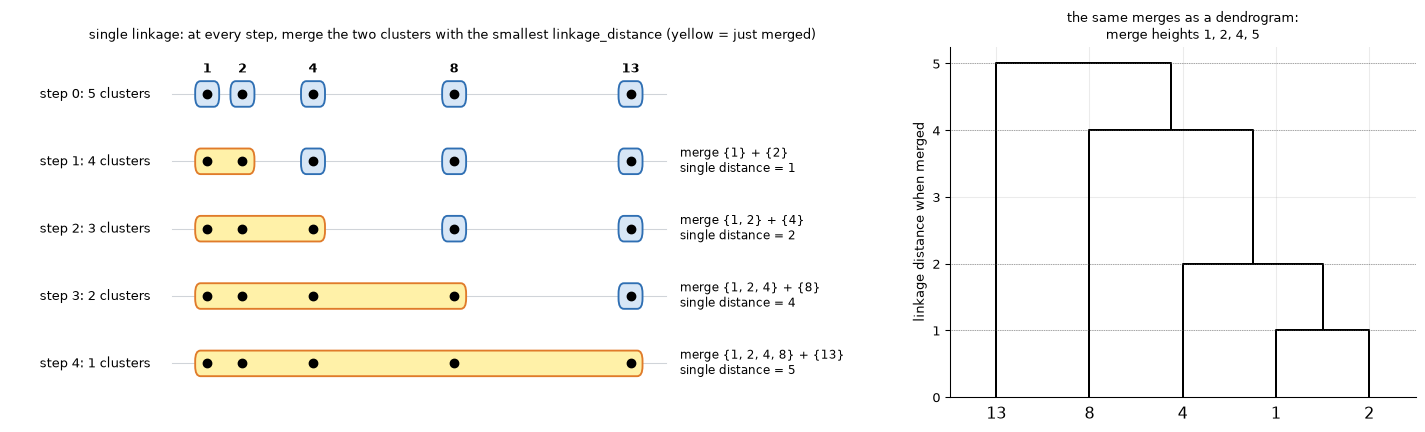

In [57]:
fig_agglomerative('single')

**Now the code.** First your function (run it), then the algorithm, with a comment on every line. It prints the same four merges as the table.

In [58]:
def linkage_distance(A, B, how):         # your Week 4 exercise 1
    pd = np.sqrt(((A[:, None, :] - B[None, :, :]) ** 2).sum(axis=2))   # (m, p): every member of A vs every member of B
    return {"single": pd.min(), "complete": pd.max(), "average": pd.mean()}[how]

In [59]:
X = np.array([[1.0], [2.0], [4.0], [8.0], [13.0]])     # (5, 1): five points, one feature
clusters = [[0], [1], [2], [3], [4]]      # a list of clusters; each cluster = a list of ROW numbers of X

while len(clusters) > 1:
    best = None                            # (distance, a, b) of the closest pair seen so far
    for a in range(len(clusters)):
        for b in range(a + 1, len(clusters)):          # b > a: each pair once
            d = linkage_distance(X[clusters[a]], X[clusters[b]], "single")   # X[list] = those rows, shape (size, 1)
            if best is None or d < best[0]:
                best = (d, a, b)
    d, a, b = best
    print(X[clusters[a]].ravel(), "+", X[clusters[b]].ravel(), "at", d)
    clusters[a] = clusters[a] + clusters[b]   # list + list = the two lists joined
    del clusters[b]                            # b > a, so removing b doesn't shift a
# → [1.] + [2.] at 1.0
# → [1. 2.] + [4.] at 2.0
# → [1. 2. 4.] + [8.] at 4.0
# → [1. 2. 4. 8.] + [13.] at 5.0

[1.] + [2.] at 1.0
[1. 2.] + [4.] at 2.0
[1. 2. 4.] + [8.] at 4.0
[1. 2. 4. 8.] + [13.] at 5.0


scipy's `linkage` runs the same algorithm (faster). It returns one row per merge: the two cluster ids, the height, and the new cluster's size. Column 2 holds the heights:

In [60]:
from scipy.cluster.hierarchy import linkage
Z = linkage(X, method="single")      # method = "single", "complete" or "average"; returns shape (n - 1, 4)
print(Z[:, 2])                       # → [1. 2. 4. 5.]

[1. 2. 4. 5.]


**Drill (on paper).** Run the same algorithm by hand with **complete** linkage on 1, 2, 4, 8, 13. Which merges happen, at which heights?

<details><summary>Worked answer</summary>

Step 1: {1}+{2} at 1. Step 2: complete distances $D(\{1,2\},\{4\}) = \max(3, 2) = 3$, $D(\{4\},\{8\}) = 4$, $D(\{8\},\{13\}) = 5$, so {1, 2}+{4} at **3**. Step 3: $D(\{1,2,4\},\{8\}) = \max(7, 6, 4) = 7$, $D(\{8\},\{13\}) = 5$, so {8}+{13} at **5**. Step 4: $D(\{1,2,4\},\{8,13\}) = d(1, 13) = 12$. Heights 1, 3, 5, 12, and the $k = 2$ cut is {1, 2, 4} and {8, 13}: a different answer from single linkage, because complete linkage refuses to stretch a cluster to 8 when 1 is so far away.

</details>

**Recipe (agglomerative clustering).** Clusters = lists of row numbers. Loop: score every pair with `linkage_distance`, merge the smallest, record its height. Stop at $k$ clusters. Then number the clusters to get one label per point.

**Exercise 3 · The closest pair of clusters.** `clusters` is a list of lists of row numbers of `X` `(n, d)`. Return `(a, b, d)`: the positions `a < b` of the two clusters with the smallest `linkage_distance(X[clusters[a]], X[clusters[b]], how)`, and that distance. Uses your `linkage_distance` (run its cell above).

**Example**: what goes in, and what should come out:
```python
X = np.array([[1.0], [2.0], [4.0], [8.0], [13.0]])
closest_pair([[0, 1], [2], [3], [4]], X, "single")      # → (0, 1, 2.0)   {1, 2} and {4}; 2.0 may show as np.float64(2.0), the same number
closest_pair([[0, 1], [2], [3], [4]], X, "complete")    # → (0, 1, 3.0)
```

In [61]:
def closest_pair(clusters, X, how):
    best = None
    for a in range(len(clusters)):
        for b in range(a + 1, len(clusters)):
            d = linkage_distance(X[clusters[a]], X[clusters[b]], how)
            if best is None or d < best[2]:
                best = (a, b, d)
    return best

In [62]:
check(3)

Exercise 3: PASS


**Exercise 4 · Agglomerative clustering.** Return the labels, **shape `(n,)`, integers**: points in the same cluster share a label (any numbering). Start from one cluster per point, merge with `closest_pair` until `k` are left. The check compares your grouping with scikit-learn's `AgglomerativeClustering(n_clusters=k, linkage=how)`.

**Example**: what goes in, and what should come out:
```python
agglomerative(X, 2, "single")      # → [0 0 0 0 1]   {1, 2, 4, 8} and {13}
agglomerative(X, 2, "complete")    # → [0 0 0 1 1]   {1, 2, 4} and {8, 13}
```

In [63]:
def agglomerative(X, k, how):
    clusters = [[i] for i in range(len(X))]
    while len(clusters) > k:
        a, b, _ = closest_pair(clusters, X, how)
        clusters[a] = clusters[a] + clusters[b]
        del clusters[b]                     # b > a, so deleting b doesn't move a
    labels = np.empty(len(X), dtype=int)
    for c, members in enumerate(clusters):
        labels[members] = c
    return labels

In [64]:
check(4)

Exercise 4: PASS


In [65]:
for n in range(1, 5):
    check(n)

Exercise 1: PASS
Exercise 2: PASS
Exercise 3: PASS
Exercise 4: PASS


---
Solutions: `solutions/00_solutions.py`. Next: `01_formula_to_numpy.ipynb`, the Python method, over the next three (light) days.